In [ ]:
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import seaborn as sns, sklearn, torch
from torch import nn
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor

torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
plt.rcParams['figure.figsize'] = (10, 4)
np.random.seed(42)
print('torch', torch.__version__, '| sklearn', sklearn.__version__)

torch 2.11.0+cpu | sklearn 1.6.1


In [ ]:
results = {}
flights = sns.load_dataset('flights')
y = pd.Series(flights['passengers'].values, index=pd.date_range('1949-01-01', periods=144, freq='MS'), name='passengers')
assert len(y) == 144 and y.sum() == 40363
train, test = y[:'1958'], y['1959':]
H = len(test)
def rmse(f,a): return float(np.sqrt(np.mean((np.asarray(f, float) - np.asarray(a, float))**2)))
def mape(f,a): return float(100*np.mean(np.abs(np.asarray(f, float) - np.asarray(a, float))/np.abs(np.asarray(a, float))))

snaive = np.tile(train.values[-12:], 2)
results['Seasonal naive'] = (rmse(snaive, test), mape(snaive,test))

In [ ]:
def make_windows(s,p):
  s = np.asarray(s,float)
  X = np.array([s[i - p:i] for i in range(p, len(s))])
  return X, s[p:]

def recursive_forecast(model, history, p, h):
  hist = list(np.asarray(history, float))
  out = []
  for _ in range(h):
    nxt = float(model.predict(np.array(hist[-p:]).reshape(1,-1))[0])
    out.append(nxt); hist.append(nxt)
  return np.array(out)

def z_of(Lser):
  Lser = np.asarray(Lser,float)
  return Lser[13:] - Lser[12:-1] - Lser[1:-12] + Lser[:-13]

def undo(z_future, Lhist):
  """Rebuild log levels month by month from forecast z and the observed history."""
  Lh = list(Lhist)
  for zt in z_future:
    Lh.append(zt + Lh[-1] + Lh[-12] - Lh[-13])
  return np.array(Lh[len(Lhist):])

p = 13
L = np.log(y.values); Ltr = L[:len(train)]
ztr = z_of(Ltr)
mz, sz = ztr.mean(), ztr.std()
Xz, tz = make_windows((ztr -mz) / sz, p)

f_zmean = np.exp(undo(np.full(H, mz), Ltr))
results['Transform, no learning'] = (rmse(f_zmean, test), mape(f_zmean, test))

lin = LinearRegression().fit(Xz, tz)
f_lin = np.exp(undo(recursive_forecast(lin, (ztr -mz) / sz, p, H) * sz + mz, Ltr))
results['Linear'] = (rmse(f_lin, test), mape(f_lin, test))

for k, (r, m) in results.items():
  print(f'{k:31s} RMSE {r:6.1f} MAPE {m:5.1f}%')
assert abs(results['Seasonal naive'][0]-77.0) < 0.05 and abs (results['Linear'][0]-67.6) < 0.05

Seasonal naive                  RMSE   77.0 MAPE  15.5%
Transform, no learning          RMSE   76.8 MAPE  15.4%
Linear                          RMSE   67.6 MAPE  13.2%


In [ ]:
def to_seq(X):
  return torch.tensor(np.asarray(X, float), dtype=torch.float32).unsqueeze(-1)

def to_target(t):
  return torch.tensor(np.asarray(t, float), dtype=torch.float32)

print('table:', Xz.shape, '-> sequence:', tuple(to_seq(Xz).shape))

table: (94, 13) -> sequence: (94, 13, 1)


In [ ]:
class RecurrentForecaster(nn.Module):
  def __init__(self, cell='lstm', hidden=16):
    super().__init__()
    layer = {'lstm': nn.LSTM, 'gru': nn.GRU, 'rnn': nn.RNN}[cell]
    self.rnn = layer(input_size=1, hidden_size=hidden, batch_first=True)
    self.head = nn.Linear(hidden, 1)
    if cell == 'lstm':
      with torch.no_grad():
        self.rnn.bias_hh_l0[hidden:2 * hidden] += 1.0
  def forward(self,x):
    out, _ = self.rnn(x)
    return self.head(out[:,-1,:].squeeze(-1))

print(RecurrentForecaster('lstm'))
print('parameters:', sum(p.numel() for p in RecurrentForecaster('lstm').parameters()))

RecurrentForecaster(
  (rnn): LSTM(1, 16, batch_first=True)
  (head): Linear(in_features=16, out_features=1, bias=True)
)
parameters: 1233


In [17]:
HIDDEN, LR, WD, MAX_EPOCHES = 16, 1e-3, 1e-4, 500
VAL_YEARS = (1956, 1957, 1958)

def fold(year):
  j = (year - 1949) * 12 - 13
  mv, sv = ztr[:j].mean(), ztr[:j].std()
  Xa, ta = make_windows((ztr[:j + 12] - mv) / sv, p)
  return (
      to_seq(Xa[:-12]),
      to_target(ta[:-12]),
      to_seq(Xa[-12:]),
      to_target(ta[-12:])
  )


def fit_net(model, X, t, epoches, Xv=None, tv=None):
  opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WD)
  hist = []

  for ep in range(epoches):
    model.train()
    opt.zero_grad()

    loss = ((model(X).squeeze(-1) - t) ** 2).mean()
    loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    opt.step()

    v = np.nan
    if Xv is not None:
      model.eval()
      with torch.no_grad():
        v = ((model(Xv).squeeze(-1) - tv) ** 2).mean().item()

    hist.append((loss.item(), v))

  return np.array(hist)


def forecast_seq(model, history, p, h):
  hist = list(np.asarray(history, float))
  out = []
  model.eval()

  with torch.no_grad():
    for _ in range(h):
      x = torch.tensor(hist[-p:], dtype=torch.float32).view(1, p, 1)
      nxt = model(x).item()
      out.append(nxt)
      hist.append(nxt)

  return np.array(out)


def fit_and_forcast(seed, cell='lstm'):
  curves = []

  for year in VAL_YEARS:
    Xf, tf, Xv, tv = fold(year)
    torch.manual_seed(seed)
    model = RecurrentForecaster(cell, HIDDEN)
    curves.append(
        fit_net(model, Xf, tf, MAX_EPOCHES, Xv, tv)[:, 1]
    )

  ep_best = int(np.argmin(np.mean(curves, axis=0))) + 1

  torch.manual_seed(seed)
  model = RecurrentForecaster(cell, HIDDEN)
  fit_net(model, to_seq(Xz), to_target(tz), ep_best)

  zf = forecast_seq(model, (ztr - mz) / sz, p, H) * sz + mz
  return np.exp(undo(zf, Ltr)), ep_best, np.array(curves)

epochs chosen on 1956-1958: 128
LSTM (seed) RMSE 84.0 MAPE 16.6%


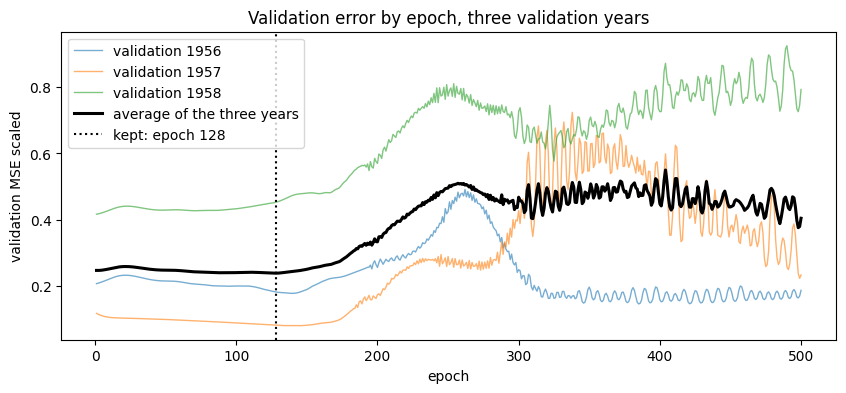

In [18]:
f_lstm0, ep0, curves0 = fit_and_forcast(0)

results['LSTM'] = (rmse(f_lstm0, test), mape(f_lstm0, test))

print(f'epochs chosen on 1956-1958: {ep0}')
print('LSTM (seed) RMSE %.1f MAPE %.1f%%' % results['LSTM'])

ep = np.arange(1, MAX_EPOCHES + 1)

for year, c in zip(VAL_YEARS, curves0):
  plt.plot(ep, c, lw=1, alpha=0.6, label=f'validation {year}')

plt.plot(ep, curves0.mean(0), 'k', lw=2.2,
         label='average of the three years')
plt.axvline(ep0, color='k', ls=':', label=f'kept: epoch {ep0}')
plt.xlabel('epoch')
plt.ylabel('validation MSE scaled')
plt.legend()
plt.title('Validation error by epoch, three validation years')
plt.show()

In [19]:
SEEDS = range(10)
runs, rmse_seed, epochs_seed = {}, {}, {}
for cell in ('lstm', 'gru'):
  out = [fit_and_forcast(seed, cell) for seed in SEEDS]
  runs[cell] = np.array([o[0] for o in out])
  rmse_seed[cell] = [rmse(f, test) for f in runs[cell]]
  epochs_seed[cell] = [o[1] for o in out]
  f_avg = np.exp(np.log(runs[cell].mean(0)))
  results[f'{cell.upper()} avg of 10 seconds'] = (rmse(f_avg, test), mape(f_avg, test))
  r = rmse_seed[cell]
  print(f'{cell.upper()}: RMSE over seeds min {min(r):.1f} median {np.median(r):.1f} max {max(r):.1f};'
        f' average of runs {results[f"{cell.upper()} avg of 10 seconds"]}; epochs {epochs_seed[cell]}')

LSTM: RMSE over seeds min 81.1 median 88.7 max 112.0; average of runs (89.9093136981715, 17.70035859581952); epochs [128, 152, 134, 134, 127, 75, 188, 101, 1, 112]
GRU: RMSE over seeds min 80.0 median 85.3 max 109.6; average of runs (87.84557508892655, 17.395619835975964); epochs [90, 65, 66, 100, 83, 13, 71, 25, 98, 97]


In [20]:
def mlp_forecast(seed):
  net = MLPRegressor(hidden_layer_sizes=(32,), activation='relu', alpha=1e-3, max_iter=5000, random_state=seed)
  net.fit(Xz, tz)
  zf = recursive_forecast(net, (ztr - mz) / sz, p, H) * sz + mz
  return np.exp(undo(zf, Ltr))

runs['mlp'] = np.array([mlp_forecast(seed) for seed in SEEDS])
rmse_seed['mlp'] = [rmse(f, test) for f in runs['mlp']]
f_mlp_avg = np.exp(np.log(runs['mlp'].mean(0)))
results['MLP'] = (rmse(f_mlp_avg, test), mape(f_mlp_avg, test))
print('MLP RMSE %.1f MAPE %.1f%%' % results['MLP'])

MLP RMSE 66.9 MAPE 12.9%


In [21]:
table = pd.DataFrame(results, index=['RMSE', 'MAPE'])
table

,Seasonal naive,"Transform, no learning",Linear,LSTM,LSTM avg of 10 seconds,GRU avg of 10 seconds,MLP
RMSE,76.994589,76.752185,67.591001,83.960559,89.909314,87.845575,66.925652
MAPE,15.523355,15.434402,13.242705,16.553503,17.700359,17.395620,12.887732


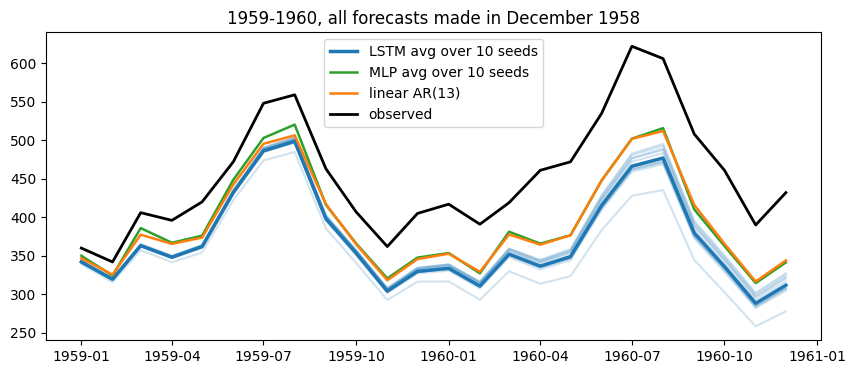

In [24]:
f_lstm_avg = np.exp(np.log(runs['lstm'].mean(0)))
plt.plot(test.index, runs['lstm'].T, color='C0', alpha=0.2)
plt.plot(test.index, f_lstm_avg, color='C0', lw=2.5, label='LSTM avg over 10 seeds')
plt.plot(test.index, f_mlp_avg, color='C2', lw=1.8, label='MLP avg over 10 seeds')
plt.plot(test.index, f_lin, color='C1', lw=1.8, label='linear AR(13)')
plt.plot(test.index, test, 'k', lw=2, label='observed')
plt.legend(); plt.title('1959-1960, all forecasts made in December 1958'); plt.show()